In [ ]:
# ========== Standard Library Imports ==========
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os ,random,re,string,nltk,cv2,shutil


# ========== Data Handling & Visualization ==========
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')


# to save models
import pickle

# ========== Scikit-learn Tools for Evaluation & Preprocessing ==========
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import label_binarize,StandardScaler,MinMaxScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,\
    f1_score ,confusion_matrix,classification_report,RocCurveDisplay,roc_curve,auc,average_precision_score,precision_recall_curve

# ========== TensorFlow / Keras for Deep Learning ==========
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing import image
from tensorflow import keras


# ========== NLP tools ==========
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from tensorflow import keras
from tqdm import tqdm
# from textblob import TextBlob


# ========== ML tools ==========
from sklearn.cluster import KMeans
from sklearn.svm import SVC ,SVR
from xgboost import XGBClassifier, XGBRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression ,LinearRegression
from sklearn.naive_bayes import GaussianNB ,ComplementNB ,CategoricalNB , MultinomialNB,BernoulliNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score,precision_score,recall_score,\
    f1_score ,confusion_matrix,classification_report,RocCurveDisplay,roc_curve,auc,mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.utils import array_to_img, img_to_array , load_img,to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator ,load_img

In [ ]:
import zipfile
import os

# Define the path to the zip file
zip_path = '/content/synthetic_cash_flow_copilot_dataset.zip'
extract_path = '/content/synthetic_cash_flow_dataset/'

# Unzip the file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# List the extracted files
print("Extracted files:")
print(os.listdir(extract_path))

Extracted files:
['synthetic_sme_expenses.csv', 'synthetic_sme_daily_cash_flow.csv', 'synthetic_sme_payments.csv', 'synthetic_sme_invoices.csv']


In [ ]:
import pandas as pd
import glob

# Find all CSV files in the extracted folder
csv_files = glob.glob(f"{extract_path}/**/*.csv", recursive=True)

if csv_files:
    # Read the first CSV file found as a demonstration
    target_file = csv_files[0]
    print(f"Reading file: {target_file}")
    df = pd.read_csv(target_file)
    display(df.head())
else:
    print("No CSV files found in the extracted directory. Please inspect the directory contents.")

Reading file: /content/synthetic_cash_flow_dataset/synthetic_sme_expenses.csv


,date,business_id,sector,expense_type,amount_egp
0,2023-01-21,SME_001,Wholesale,supplier_payments_egp,8851.43
1,2023-01-22,SME_001,Wholesale,supplier_payments_egp,7537.35
2,2023-01-23,SME_001,Wholesale,supplier_payments_egp,5364.90
3,2023-01-24,SME_001,Wholesale,supplier_payments_egp,7209.85
4,2023-01-25,SME_001,Wholesale,supplier_payments_egp,6609.68


In [ ]:
import pandas as pd

# Define paths to all four extracted files
payments_path = '/content/synthetic_cash_flow_dataset/synthetic_sme_payments.csv'
cash_flow_path = '/content/synthetic_cash_flow_dataset/synthetic_sme_daily_cash_flow.csv'
expenses_path = '/content/synthetic_cash_flow_dataset/synthetic_sme_expenses.csv'
invoices_path = '/content/synthetic_cash_flow_dataset/synthetic_sme_invoices.csv'

# Load each file into its own DataFrame
df_payments = pd.read_csv(payments_path)
df_cash_flow = pd.read_csv(cash_flow_path)
df_expenses = pd.read_csv(expenses_path)
df_invoices = pd.read_csv(invoices_path)

# Print summary info for each loaded dataset
for name, df_temp in [
    ("Payments", df_payments),
    ("Daily Cash Flow", df_cash_flow),
    ("Expenses", df_expenses),
    ("Invoices", df_invoices)
]:
    print(f"=== {name} ===")
    print(f"Shape: {df_temp.shape}")
    print(f"Columns: {list(df_temp.columns)}")
    print()


=== Payments ===
Shape: (8764, 6)
Columns: ['payment_id', 'business_id', 'payment_date', 'invoice_id', 'amount_egp', 'payment_delay_days']

=== Daily Cash Flow ===
Shape: (8768, 22)
Columns: ['date', 'business_id', 'sector', 'day_of_week', 'month', 'is_weekend', 'sales_egp', 'cash_sales_egp', 'receivables_created_egp', 'receivables_collected_egp', 'supplier_payables_created_egp', 'supplier_payments_egp', 'payroll_egp', 'rent_egp', 'taxes_egp', 'loan_payments_egp', 'other_income_egp', 'total_cash_inflow_egp', 'total_cash_outflow_egp', 'net_cash_flow_egp', 'closing_cash_balance_egp', 'promotion_flag']

=== Expenses ===
Shape: (7636, 5)
Columns: ['date', 'business_id', 'sector', 'expense_type', 'amount_egp']

=== Invoices ===
Shape: (8768, 11)
Columns: ['invoice_id', 'business_id', 'invoice_date', 'due_date', 'paid_date', 'customer_id', 'invoice_amount_egp', 'amount_paid_egp', 'payment_delay_days', 'is_late', 'status']



In [ ]:
# Display a preview of each dataset
print("Payments Preview:")
display(df_payments.head(2))

print("\nDaily Cash Flow Preview:")
display(df_cash_flow.head(2))

print("\nExpenses Preview:")
display(df_expenses.head(2))

print("\nInvoices Preview:")
display(df_invoices.head(2))

Payments Preview:


,payment_id,business_id,payment_date,invoice_id,amount_egp,payment_delay_days
0,PAY_0000001,SME_001,2023-01-31,INV_SME_001_20230101_0000,3536.77,0
1,PAY_0000002,SME_001,2023-02-08,INV_SME_001_20230102_0001,6580.53,7



Daily Cash Flow Preview:


,date,business_id,sector,day_of_week,month,is_weekend,sales_egp,cash_sales_egp,receivables_created_egp,receivables_collected_egp,...,payroll_egp,rent_egp,taxes_egp,loan_payments_egp,other_income_egp,total_cash_inflow_egp,total_cash_outflow_egp,net_cash_flow_egp,closing_cash_balance_egp,promotion_flag
0,2023-01-01,SME_001,Wholesale,6,1,1,12682.52,6395.56,3622.22,0.0,...,0.0,22224.47,0.0,0.0,0.0,6395.56,24700.35,-18304.79,191695.21,0
1,2023-01-02,SME_001,Wholesale,0,1,0,12049.91,6581.06,7015.34,0.0,...,0.0,0.00,0.0,0.0,0.0,6581.06,2155.21,4425.85,196121.06,0



Expenses Preview:


,date,business_id,sector,expense_type,amount_egp
0,2023-01-21,SME_001,Wholesale,supplier_payments_egp,8851.43
1,2023-01-22,SME_001,Wholesale,supplier_payments_egp,7537.35



Invoices Preview:


,invoice_id,business_id,invoice_date,due_date,paid_date,customer_id,invoice_amount_egp,amount_paid_egp,payment_delay_days,is_late,status
0,INV_SME_001_20230101_0000,SME_001,2023-01-01,2023-01-31,2023-01-31,CUST_045,3622.22,3536.77,0,0,paid
1,INV_SME_001_20230102_0001,SME_001,2023-01-02,2023-02-01,2023-02-08,CUST_021,7015.34,6580.53,7,1,paid


In [ ]:
df=df_payments
df1=df_cash_flow
df2=df_expenses
df3=df_invoices

In [ ]:
df.head()

,payment_id,business_id,payment_date,invoice_id,amount_egp,payment_delay_days
0,PAY_0000001,SME_001,2023-01-31,INV_SME_001_20230101_0000,3536.77,0
1,PAY_0000002,SME_001,2023-02-08,INV_SME_001_20230102_0001,6580.53,7
2,PAY_0000003,SME_001,2023-02-17,INV_SME_001_20230103_0002,9817.09,0
3,PAY_0000004,SME_001,2023-02-03,INV_SME_001_20230104_0003,8887.91,0
4,PAY_0000005,SME_001,2023-02-19,INV_SME_001_20230105_0004,3874.79,0


In [ ]:
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
amount_egp,7636.0,9250.985361,6735.027146,1050.42,4444.1925,7160.885,11905.265,41819.25


In [ ]:
df2.head()

,date,business_id,sector,expense_type,amount_egp
0,2023-01-21,SME_001,Wholesale,supplier_payments_egp,8851.43
1,2023-01-22,SME_001,Wholesale,supplier_payments_egp,7537.35
2,2023-01-23,SME_001,Wholesale,supplier_payments_egp,5364.90
3,2023-01-24,SME_001,Wholesale,supplier_payments_egp,7209.85
4,2023-01-25,SME_001,Wholesale,supplier_payments_egp,6609.68


In [ ]:
df2.shape

(7636, 5)

In [ ]:
df2['sector'].value_counts()

,count
sector,
Retail,1914
Services,1909
Wholesale,1899
Ecommerce,958
Distribution,956


In [ ]:
df2.isnull().sum()

,0
date,0
business_id,0
sector,0
expense_type,0
amount_egp,0


In [ ]:
df2.duplicated().sum()

np.int64(0)

In [ ]:
df2['expense_type'].value_counts()

,count
expense_type,
supplier_payments_egp,6100
payroll_egp,864
rent_egp,288
loan_payments_egp,288
taxes_egp,96


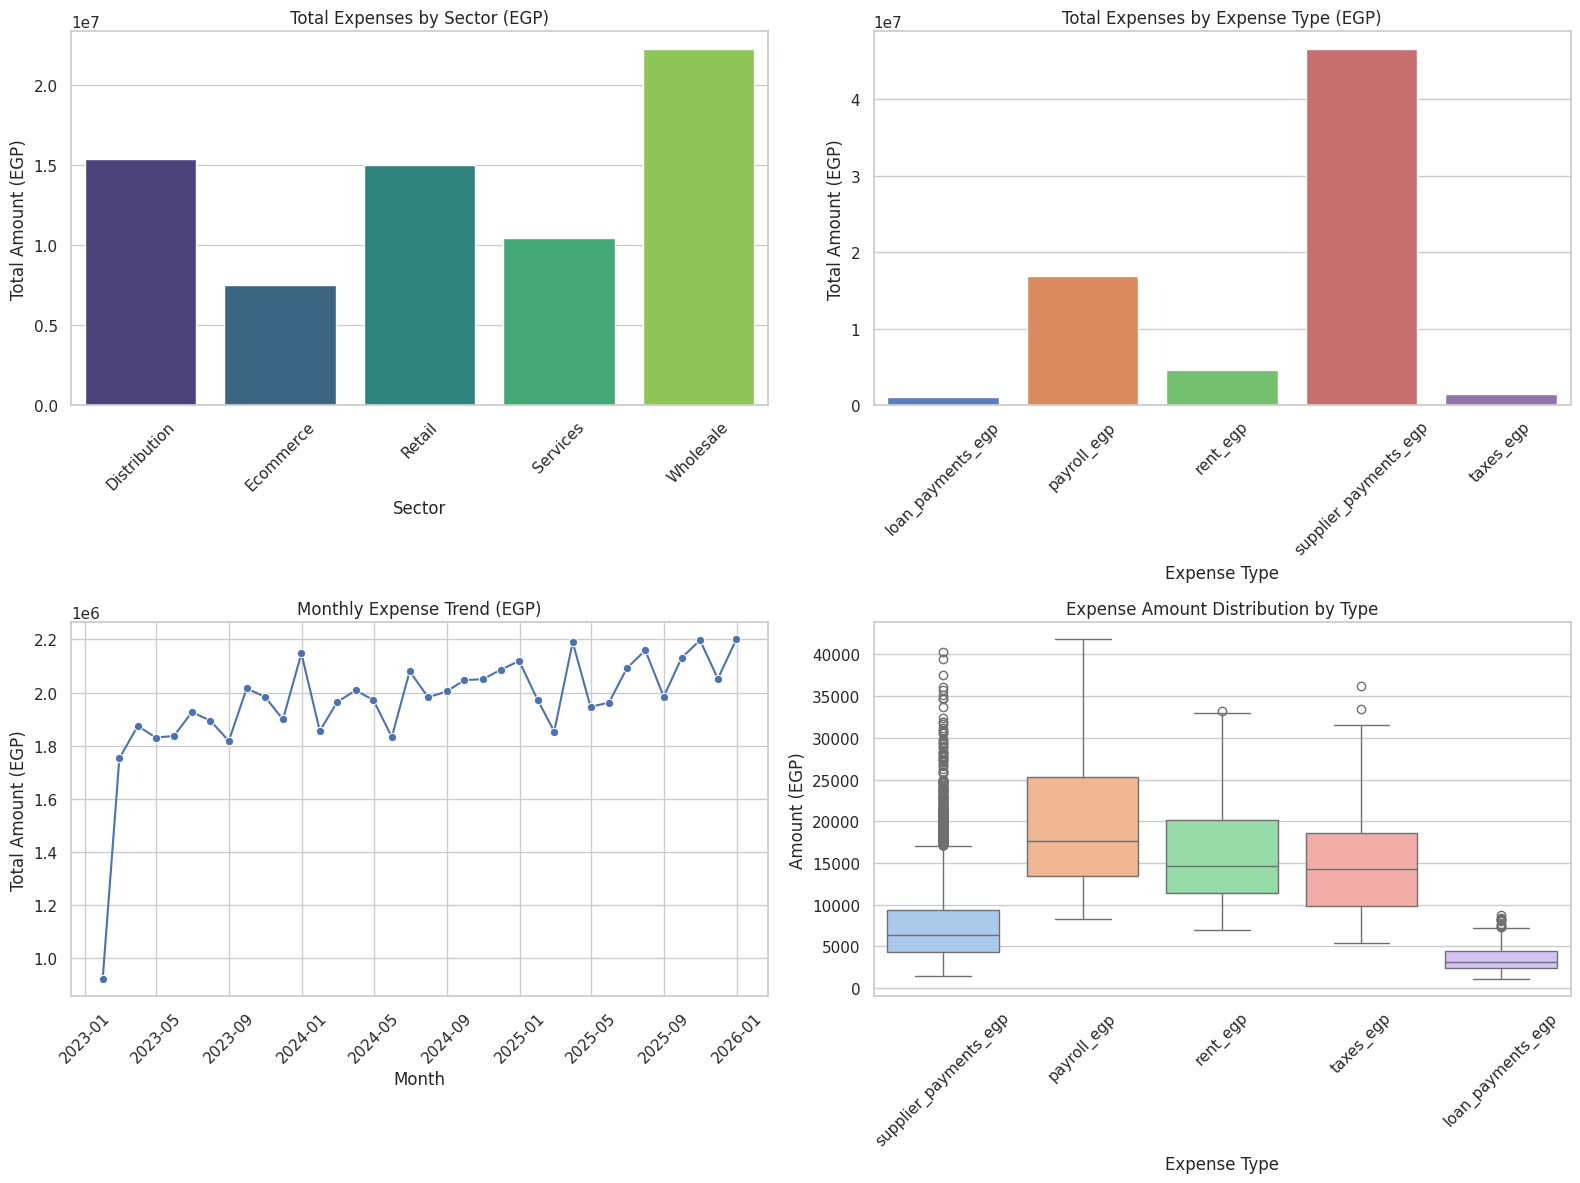

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure the date column is parsed as datetime
df2['date'] = pd.to_datetime(df2['date'])

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of Expenses by Sector
sns.barplot(
    ax=axes[0, 0],
    x=df2.groupby('sector')['amount_egp'].sum().index,
    y=df2.groupby('sector')['amount_egp'].sum().values,
    hue=df2.groupby('sector')['amount_egp'].sum().index,
    palette='viridis',
    legend=False
)
axes[0, 0].set_title('Total Expenses by Sector (EGP)')
axes[0, 0].set_xlabel('Sector')
axes[0, 0].set_ylabel('Total Amount (EGP)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Distribution of Expenses by Expense Type
sns.barplot(
    ax=axes[0, 1],
    x=df2.groupby('expense_type')['amount_egp'].sum().index,
    y=df2.groupby('expense_type')['amount_egp'].sum().values,
    hue=df2.groupby('expense_type')['amount_egp'].sum().index,
    palette='muted',
    legend=False
)
axes[0, 1].set_title('Total Expenses by Expense Type (EGP)')
axes[0, 1].set_xlabel('Expense Type')
axes[0, 1].set_ylabel('Total Amount (EGP)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Monthly Expense Trend
df2_monthly = df2.set_index('date').resample('ME')['amount_egp'].sum().reset_index()
sns.lineplot(
    ax=axes[1, 0],
    data=df2_monthly,
    x='date',
    y='amount_egp',
    marker='o',
    color='b'
)
axes[1, 0].set_title('Monthly Expense Trend (EGP)')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Total Amount (EGP)')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Boxplot of Expense Amounts by Expense Type to see outliers/distribution
sns.boxplot(
    ax=axes[1, 1],
    data=df2,
    x='expense_type',
    y='amount_egp',
    hue='expense_type',
    palette='pastel',
    legend=False
)
axes[1, 1].set_title('Expense Amount Distribution by Type')
axes[1, 1].set_xlabel('Expense Type')
axes[1, 1].set_ylabel('Amount (EGP)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
X=df2.drop('amount_egp',axis=1)
y=df2['amount_egp']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [ ]:
from sklearn.preprocessing import LabelEncoder

# Make a copy of df2 to apply encoding directly
df2_encoded = df2.copy()

# Ensure date is parsed and extract features
df2_encoded['date'] = pd.to_datetime(df2_encoded['date'])
df2_encoded['year'] = df2_encoded['date'].dt.year
df2_encoded['month'] = df2_encoded['date'].dt.month
df2_encoded['day'] = df2_encoded['date'].dt.day
df2_encoded.drop(columns=['date'], inplace=True)

# Apply LabelEncoder to 'business_id', 'sector', and 'expense_type'
le_dict = {}
for col in ['business_id', 'sector', 'expense_type']:
    le = LabelEncoder()
    df2_encoded[col] = le.fit_transform(df2_encoded[col])
    le_dict[col] = le

# Display the encoded df2
print("df2 Encoded Preview:")
display(df2_encoded.head())

df2 Encoded Preview:


,business_id,sector,expense_type,amount_egp,year,month,day
0,0,4,3,8851.43,2023,1,21
1,0,4,3,7537.35,2023,1,22
2,0,4,3,5364.90,2023,1,23
3,0,4,3,7209.85,2023,1,24
4,0,4,3,6609.68,2023,1,25


In [ ]:
# Separating features (X) and target (y) from our completely encoded df2_encoded DataFrame
X = df2_encoded.drop('amount_egp', axis=1)
y = df2_encoded['amount_egp']

# Splitting the data into train and test sets (entirely numerical now)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train and Test sets split and encoded successfully!")
print(f"X_train shape: {X_train.shape}")

Train and Test sets split and encoded successfully!
X_train shape: (6108, 6)


In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Separate features (X) and target (y) from the encoded df2
X = df2_encoded.drop(columns=['amount_egp'])
y = df2_encoded['amount_egp']

# 2. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and fit the StandardScaler on training data, then transform both train and test sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames for easy visualization/handling
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

print("=== Data Scaling Complete ===")
print(f"Scaled X_train shape: {X_train_scaled_df.shape}")
print(f"Scaled X_test shape: {X_test_scaled_df.shape}")

print("\nPreview of Scaled X_train:")
display(X_train_scaled_df.head())

=== Data Scaling Complete ===
Scaled X_train shape: (6108, 6)
Scaled X_test shape: (1528, 6)

Preview of Scaled X_train:


,business_id,sector,expense_type,date_year,date_month,date_day
0,0.655138,1.240947,0.434474,1.209329,0.700578,-1.007510
1,1.092804,0.484565,0.434474,1.209329,-0.771128,1.412848
2,-1.533193,1.240947,0.434474,-0.021768,0.700578,-0.457429
3,-1.533193,1.240947,0.434474,1.209329,-1.654151,-0.457429
4,1.092804,0.484565,0.434474,-0.021768,1.583602,-1.667608


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the models we want to train
models = {
    'Linear Regression': LinearRegression(),
    'SVR': SVR(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42, n_estimators=100),
    'XGBoost Regressor': XGBRegressor(random_state=42)
}

# Dictionary to store performance metrics
results = {}

print("=== Training Regression Models ===\n")

for name, model in models.items():
    print(f"Training {name}...")
    # Fit the model on the scaled training features and target values
    model.fit(X_train_scaled, y_train)

    # Make predictions on test set
    predictions = model.predict(X_test_scaled)

    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results[name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

# Convert results into a DataFrame for easy comparison
results_df = pd.DataFrame(results).T
print("\n=== Model Comparison Results ===")
display(results_df.sort_values(by='R2 Score', ascending=False))

=== Training Regression Models ===

Training Linear Regression...
Training SVR...
Training Decision Tree Regressor...
Training Random Forest Regressor...
Training XGBoost Regressor...

=== Model Comparison Results ===


,MAE,MSE,RMSE,R2 Score
XGBoost Regressor,2893.584756,1.576761e+07,3970.845297,0.628336
Random Forest Regressor,2932.228034,1.589166e+07,3986.434598,0.625412
Decision Tree Regressor,3599.356695,2.678901e+07,5175.810020,0.368546
Linear Regression,4595.177825,3.761201e+07,6132.863342,0.113433
SVR,4588.954919,4.442645e+07,6665.316799,-0.047193


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

print("=== Starting Hyperparameter Fine-tuning ===\n")

# 1. Fine-tuning XGBoost
xgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

print("Tuning XGBoost Regressor...")
xgb_grid = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_distributions=xgb_param_dist,
    n_iter=10,
    scoring='r2',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)
xgb_grid.fit(X_train_scaled, y_train)

best_xgb = xgb_grid.best_estimator_
xgb_predictions = best_xgb.predict(X_test_scaled)
xgb_r2 = r2_score(y_test, xgb_predictions)

print(f"Best XGBoost Params: {xgb_grid.best_params_}")
print(f"XGBoost Fine-tuned R2 Score: {xgb_r2:.4f}\n")

# 2. Fine-tuning Random Forest
rf_param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

print("Tuning Random Forest Regressor...")
rf_grid = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=rf_param_dist,
    n_iter=10,
    scoring='r2',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
rf_predictions = best_rf.predict(X_test_scaled)
rf_r2 = r2_score(y_test, rf_predictions)

print(f"Best Random Forest Params: {rf_grid.best_params_}")
print(f"Random Forest Fine-tuned R2 Score: {rf_r2:.4f}\n")

=== Starting Hyperparameter Fine-tuning ===

Tuning XGBoost Regressor...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best XGBoost Params: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
XGBoost Fine-tuned R2 Score: 0.6916

Tuning Random Forest Regressor...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Random Forest Params: {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 10}
Random Forest Fine-tuned R2 Score: 0.6821



In [ ]:
import pickle

# 1. Save the best fine-tuned XGBoost model
with open('best_xgb_model.pkl', 'wb') as f:
    pickle.dump(best_xgb, f)

# 2. Save the fitted scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Saved 'best_xgb_model.pkl' and 'scaler.pkl' successfully!")

Saved 'best_xgb_model.pkl' and 'scaler.pkl' successfully!


In [ ]:
# Install FastAPI and Uvicorn
!pip install fastapi uvicorn nest-asyncio

In [ ]:
%%writefile app.py
from fastapi import FastAPI
from pydantic import BaseModel
import pickle
import numpy as np
import pandas as pd

app = FastAPI(
    title="SME Expenses Predictor API",
    description="FastAPI for predicting SME expense amounts (amount_egp) using fine-tuned XGBoost",
    version="1.0.0"
)

# Load the saved model and scaler
with open('best_xgb_model.pkl', 'rb') as f:
    model = pickle.load(f)

with open('scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

# Define the input data schema matching the training features
class PredictionInput(BaseModel):
    business_id: int
    sector: int
    expense_type: int
    date_year: int
    date_month: int
    date_day: int

@app.get("/")
def home():
    return {"message": "Welcome to the SME Expenses Predictor API! Use the /predict endpoint to get predictions."}

@app.post("/predict")
def predict(data: PredictionInput):
    # Convert input data to array/DataFrame matching original feature format
    input_data = np.array([[
        data.business_id,
        data.sector,
        data.expense_type,
        data.date_year,
        data.date_month,
        data.date_day
    ]])

    # Scale features
    scaled_data = scaler.transform(input_data)

    # Make prediction
    prediction = model.predict(scaled_data)[0]

    return {
        "predicted_amount_egp": float(prediction)
    }

Overwriting app.py


### طريقة تشغيل الـ FastAPI في Colab

لتشغيل خادم FastAPI هنا مباشرة في Colab، هنستخدم `nest_asyncio` و `uvicorn` كالتالي في الخلية القادمة:

In [ ]:
import threading
import uvicorn
import time

# Configure uvicorn server on port 8001 to avoid address already in use conflict
config = uvicorn.Config("app:app", host="127.0.0.1", port=8001, log_level="info", reload=False)
server = uvicorn.Server(config)

# Run the server inside a background thread
def run_server():
    server.run()

# Start thread
thread = threading.Thread(target=run_server, daemon=True)
thread.start()

print("FastAPI Server is starting in a separate background thread on port 8001...")
time.sleep(2)  # Give the server a couple of seconds to bind to the port

INFO:     Started server process [2282]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8001 (Press CTRL+C to quit)


FastAPI Server is starting in a separate background thread on port 8001...


In [ ]:
import requests
import json

# 1. Define the local endpoint URL on the updated port 8001
url = 'http://127.0.0.1:8001/predict'

# 2. Define a sample input payload
payload = {
    "business_id": 2,
    "sector": 3,
    "expense_type": 1,
    "date_year": 2024,
    "date_month": 5,
    "date_day": 15
}

try:
    # Send POST request
    response = requests.post(url, json=payload, timeout=5)

    # Display response
    print("Status Code:", response.status_code)
    print("Prediction Response:")
    print(json.dumps(response.json(), indent=4))
except Exception as e:
    print("An error occurred while testing the API:", e)

INFO:     127.0.0.1:56602 - "POST /predict HTTP/1.1" 200 OK
Status Code: 200
Prediction Response:
{
    "predicted_amount_egp": 14311.962890625
}
